# [15.4] LoRA Phase Transitions and Misalignment Proxies (solutions)

> **Colab:
> [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter15_peft_misalignment/exercises/part4_lora_phase_transitions/15.4_LoRA_Phase_Transitions_and_Misalignment_Proxies_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter15_peft_misalignment/exercises/part4_lora_phase_transitions/15.4_LoRA_Phase_Transitions_and_Misalignment_Proxies_solutions.ipynb)**

> **Prediction practice: [start the guided workbook](../../../mastery_hub/units/extension_predictions/exercises.ipynb#section-15-4) before viewing this lesson's results.**
> Record a forecast, confidence and reasoning, then compare controls and predict a changed case. These reference-rich lessons support guided practice; prior exposure is not scored as unseen mastery.

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

<img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/headers/header-15-3.png" width="350">

# Introduction

Imagine watching a narrow task improve smoothly while many other answers change over just two saved checkpoints. Is the adapter learning a new behavior all at once? Or did a smoothly changing score cross the decision boundaries of many examples at nearly the same time?

By the end of this notebook, you will have shown that **a smooth, planted low-rank adapter trajectory can produce an apparently abrupt benign proxy-label change**, and that removing a known output direction can restore the proxy while preserving the narrow task, unlike an indiscriminate spectral intervention. You will see singular values and label changes together, with zero-adapter, rank-limited and same-norm random controls.

Our concrete proxy is deliberately harmless: a linear readout chooses **amber** when its margin is positive and **teal** otherwise. A second readout predicts a number on the narrow task. These labels are not judgments of alignment, and this matrix is not an LLM. The trajectory is authored explicitly; there is no optimizer and no claim that training discovered a phase transition. This makes every causal claim in the small example checkable before you face the much harder problem of measuring behavior in a pretrained model.

Prerequisites: matrix multiplication and SVD from 0.1; the $BA$ convention and scaling from 15.1; the distinction between weight-space and behavioral measurements in 15.2. NumPy operations use float64 on CPU. Nothing in the default route downloads or loads a pretrained model. The configured requirements `training.lora_phase_transitions` and `peft.safe_lora_misalignment_proxy` motivate this study exercise; their trained-model replication remains pending.

Before opening the reference plots, write down your forecast: on our nine checkpoints, will the first 50% proxy-flip checkpoint coincide with the first checkpoint where the proxy mode becomes the largest singular mode? Explain why these two events might differ. These public reference outputs make this guided practice, not an unseen assessment.

## Content & Learning Objectives

### 1️⃣ Adapter geometry

Build a scaled adapter, an explicit two-mode trajectory and a best-rank approximation. Inspect what rank actually limits, and what it does not.

> ##### Learning Objectives
>
> - Implement $\Delta W=(\alpha/r)BA$ with output-by-input weights.
> - Separate singular-value energy from a behavior direction.
> - Construct a control with the same rank and Frobenius norm.

### 2️⃣ A measured onset

Define the benign behavior readout before looking at the curve, then turn margins into label flips and detect the first sampled threshold crossing.

> ##### Learning Objectives
>
> - Freeze a label rule, denominator and threshold before measuring onset.
> - Distinguish sampled crossing time from a dynamical phase transition.
> - Compare scores and labels to diagnose an apparent discontinuity.

### 3️⃣ Causal intervention

Use output-direction removal and dominant-SVD-mode removal to ask which part of the adapter changes the proxy, and what narrow-task cost each intervention pays.

> ##### Learning Objectives
>
> - Implement sign-invariant alignment and output projection.
> - Compare targeted and unspecific interventions on both readouts.

### 4️⃣ Prediction and scope

Reconstruct all curves from the functions you wrote, then change the decision thresholds while leaving the adapter untouched.

> ##### Learning Objectives
>
> - Explain a mismatch between spectral and behavioral onset.
> - State the additional model, data and behavioral evidence needed for an emergent-misalignment claim.

### ☆ Bonus

Explore basis changes and baseline sensitivity without silently upgrading this analytic fixture into trained-model evidence.

## Setup code

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

chapter = 'chapter15_peft_misalignment'
section = 'part4_lora_phase_transitions'
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).is_dir())
exercises_dir = root_dir / chapter / 'exercises'
if str(exercises_dir) not in sys.path:
    sys.path.insert(0, str(exercises_dir))
import part4_lora_phase_transitions.tests as tests
import part4_lora_phase_transitions.utils as utils
MAIN = __name__ == '__main__'
np.set_printoptions(precision=4, suppress=True)

# 1️⃣ Adapter geometry

> ##### Learning Objectives
>
> - Implement $\Delta W=(\alpha/r)BA$ with output-by-input weights.
> - Separate singular-value energy from a behavior direction.
> - Construct a control with the same rank and Frobenius norm.

## From a bottleneck to an update

A frozen linear module maps input rows $X\in\mathbb R^{n\times d_{in}}$ to $XW_0^\top$. LoRA adds $\Delta W=(\alpha/r)BA$, with $A\in\mathbb R^{r\times d_{in}}$ and $B\in\mathbb R^{d_{out}\times r}$. Therefore the adapted output is $X(W_0+\Delta W)^\top$. The bottleneck constrains matrix rank, not the number of prompts or behaviors that can change: many inputs can activate the same bottleneck coordinate.

We use output-by-input matrices throughout. Reversing $BA$ and $AB$ is not a convention change when dimensions differ; it is a different map. Our tests deliberately include rectangular factors and nonunit scaling.

### Exercise - implement `lora_update`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10-15 minutes on this exercise.
> ```

Return the dense output-by-input update from factors `A` of shape `(r, din)` and `B` of shape `(dout, r)`. Divide by the factor rank, not the input dimension.

In [2]:
def lora_update(A, B, alpha):
    r = A.shape[0]
    return (alpha / r) * (B @ A)

tests.test_lora_update(lora_update)

All tests in `test_lora_update` passed!


<details><summary>Hint</summary>

Compute the dense update only for this tiny analysis. A real LoRA forward can apply the factors without materializing it.

</details>

<details><summary>Expected output</summary>

For rank 2, alpha 1, the test update is `[[0.5, 4, 0.5], [-0.5, -1, 0.5]]`. The immediate tests print `All tests in test_lora_update passed!` (with the function name in backticks).

</details>

<details><summary>Help - why this step matters</summary>

Return the dense output-by-input update from factors `A` of shape `(r, din)` and `B` of shape `(dout, r)`. Divide by the factor rank, not the input dimension. Keep the quantity's units and its comparison condition explicit before interpreting a change.

</details>

## An authored trajectory with two meanings

Let $e_i$ denote coordinate $i$ in four-dimensional input and output spaces. At normalized checkpoint time $t\in[0,1]$ set

$$\Delta W(t)=t e_0e_0^\top+2.4\max(t-0.5,0)e_1e_1^\top.$$

The first term improves our narrow task; the second changes the amber/teal proxy. Both coefficients are continuous. The second coefficient has a deliberately planted slope change at $t=0.5$. Calling it a learned phase transition would erase the most important fact about the fixture: **we put it there**. The exercise is to learn how a detector and an intervention behave when the mechanism is known, not to discover a new training phenomenon.

The matrix has rank at most two. It can be represented by LoRA factors using the first two basis vectors for $A$, the corresponding scaled output vectors for $B$, and $\alpha=2$. The diagonal construction is a useful ground truth, but real adapter singular vectors need not align with interpretable behavior axes.

### Exercise - implement `planted_update`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10-15 minutes on this exercise.
> ```

Return the explicit `(4,4)` update above at a scalar checkpoint time. Use a positive-part function so the second mode is exactly zero through time 0.5.

In [3]:
def planted_update(time):
    return np.diag([time, 2.4 * max(time - 0.5, 0.0), 0.0, 0.0])

tests.test_planted_update(planted_update)

All tests in `test_planted_update` passed!


<details><summary>Hint</summary>

The function specifies a fixture; it does not simulate gradient descent.

</details>

<details><summary>Expected output</summary>

At time 0.75 the diagonal is `[0.75, 0.6, 0, 0]`; at time 1 it is `[1, 1.2, 0, 0]`. The immediate tests print `All tests in test_planted_update passed!` (with the function name in backticks).

</details>

<details><summary>Help - why this step matters</summary>

Return the explicit `(4,4)` update above at a scalar checkpoint time. Use a positive-part function so the second mode is exactly zero through time 0.5. Keep the quantity's units and its comparison condition explicit before interpreting a change.

</details>

### Exercise - implement `rank_projection`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10-15 minutes on this exercise.
> ```

Return the best rank-at-most-`rank` approximation in Frobenius norm using a reduced SVD. Rank zero must return the zero matrix. This control asks how much a rank constraint alone changes the mechanism.

In [4]:
def rank_projection(update, rank):
    U, singular, Vh = np.linalg.svd(update, full_matrices=False)
    return (U[:, :rank] * singular[:rank]) @ Vh[:rank]

tests.test_rank_projection(rank_projection)

All tests in `test_rank_projection` passed!


<details><summary>Hint</summary>

Multiply columns of U by the retained singular values. The omitted squared singular values give the squared residual norm.

</details>

<details><summary>Expected output</summary>

For diagonal `[1,4,2]`, rank 1 retains only the middle coordinate. Rank 2 leaves residual squared norm 1. The immediate tests print `All tests in test_rank_projection passed!` (with the function name in backticks).

</details>

<details><summary>Help - why this step matters</summary>

Return the best rank-at-most-`rank` approximation in Frobenius norm using a reduced SVD. Rank zero must return the zero matrix. This control asks how much a rank constraint alone changes the mechanism. Keep the quantity's units and its comparison condition explicit before interpreting a change.

</details>

In [5]:
times = np.linspace(0., 1., 9)
updates = np.stack([planted_update(time) for time in times])
print('time  narrow coefficient  proxy coefficient  rank')
for time, update in zip(times, updates):
    print(f'{time:4.3f}       {update[0,0]:5.3f}             {update[1,1]:5.3f}       {np.linalg.matrix_rank(update)}')

time  narrow coefficient  proxy coefficient  rank
0.000       0.000             0.000       0
0.125       0.125             0.000       1
0.250       0.250             0.000       1
0.375       0.375             0.000       1
0.500       0.500             0.000       1
0.625       0.625             0.300       2
0.750       0.750             0.600       2
0.875       0.875             0.900       2
1.000       1.000             1.200       2


<details><summary>Expected output</summary>

The first row is zero with rank 0. Time 0.500 has coefficients 0.500 and 0.000, rank 1. Time 0.750 has 0.750 and 0.600, rank 2. Time 1.000 has 1.000 and 1.200, rank 2.

</details>

## Summary of 1️⃣

Low rank constrains an update's subspace. The same small subspace can affect many contexts. Our planted trajectory cleanly separates a task coefficient and a proxy coefficient, so the next part can test measurement without uncertainty about training.

# 2️⃣ A measured onset

> ##### Learning Objectives
>
> - Freeze a label rule, denominator and threshold before measuring onset.
> - Distinguish sampled crossing time from a dynamical phase transition.
> - Compare scores and labels to diagnose an apparent discontinuity.

## A spectrum is a size measurement

For singular values $s_i$, define energy fractions $E_i=s_i^2/\sum_j s_j^2$. These fractions describe the Frobenius geometry of the *update*, not explained behavioral variance. A singular value can be large because a direction is heavily scaled even if our input distribution never visits that direction. For a zero update, return zero fractions: no axis has any update energy, and dividing by zero would fabricate a distribution.

### Exercise - implement `spectral_energy`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10-15 minutes on this exercise.
> ```

Return descending singular-value energy fractions of an update. The output length is `min(dout, din)`; use zeros when the update is zero.

In [6]:
def spectral_energy(update):
    squared = np.linalg.svd(update, compute_uv=False) ** 2
    return squared / squared.sum() if squared.sum() > 0 else np.zeros_like(squared)

tests.test_spectral_energy(spectral_energy)

All tests in `test_spectral_energy` passed!


<details><summary>Hint</summary>

Use squared singular values, not singular values themselves.

</details>

<details><summary>Expected output</summary>

Diagonal `[3,4,0]` gives `[0.64,0.36,0]`, including the zero direction. The immediate tests print `All tests in test_spectral_energy passed!` (with the function name in backticks).

</details>

<details><summary>Help - why this step matters</summary>

Return descending singular-value energy fractions of an update. The output length is `min(dout, din)`; use zeros when the update is zero. Keep the quantity's units and its comparison condition explicit before interpreting a change.

</details>

## A rank- and norm-matched negative control

If a random adapter has a smaller norm than the target adapter, a smaller effect is unsurprising. Our control draws two orthonormal bases by QR factorization, combines the first `rank` columns into a random low-rank map, and scales the result to the target Frobenius norm. The random map has equal nonzero singular values; it matches rank and total norm, **not** the entire singular spectrum.

At every checkpoint, use the planted update's actual numerical rank: zero at time 0, rank 1 through time 0.5, and rank 2 afterwards. Reuse seed 17, so the control direction is fixed within each rank while its norm tracks the target. Its direction changes when the required rank increases; that change belongs to the rank-matched null and is not an independently sampled training event. One seed is an illustration, not a distributional random-control study. Keep a failed random control visible if its projection happens to affect the proxy.

### Exercise - implement `matched_random_update`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10-15 minutes on this exercise.
> ```

Return a seeded random update with the same shape and Frobenius norm as `update` and the requested rank. Use QR bases and normalize the final matrix. Return zero when the target has zero norm.

In [7]:
def matched_random_update(update, rank, seed):
    if np.linalg.norm(update) == 0:
        return np.zeros_like(update)
    rng = np.random.default_rng(seed)
    left = np.linalg.qr(rng.normal(size=(update.shape[0], rank)))[0]
    right = np.linalg.qr(rng.normal(size=(update.shape[1], rank)))[0]
    random = left @ right.T
    return random * (np.linalg.norm(update) / np.linalg.norm(random))

tests.test_matched_random_update(matched_random_update)

All tests in `test_matched_random_update` passed!


<details><summary>Hint</summary>

The rank of `left @ right.T` is the number of selected orthonormal columns.

</details>

<details><summary>Expected output</summary>

The norm-5 diagonal fixture produces a deterministic rank-2 random matrix of norm 5, with a different direction. The immediate tests print `All tests in test_matched_random_update passed!` (with the function name in backticks).

</details>

<details><summary>Help - why this step matters</summary>

Return a seeded random update with the same shape and Frobenius norm as `update` and the requested rank. Use QR bases and normalize the final matrix. Return zero when the target has zero norm. Keep the quantity's units and its comparison condition explicit before interpreting a change.

</details>

## Freeze the behavioral rule

Our proxy has 24 contexts, all with input $x=e_1$, but each with a different context-specific decision threshold $\tau_i$ equally spaced from 0.1 through 1.1. Given the output readout $q=e_1$,

$$m_i=x_i^\top W^\top q-\tau_i,\qquad c_i=\mathbb 1[m_i>0].$$

A positive margin chooses amber. Zero and negative margins choose teal. The zero base matrix $W_0$ chooses teal in every context. Context thresholds model a fixed downstream offset, not independent training examples. Count each of the 24 contexts once: no averaging over coordinates, no cherry-picked examples and no relabeling these public examples as untouched TEST.

A proxy flip means only that an amber/teal label changed relative to the base. It is not an unsafe answer. Because the thresholds are spread out, a single continuous score produces a stepped label-fraction curve.

### Exercise - implement `proxy_margins`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10-15 minutes on this exercise.
> ```

Compute one margin per example from inputs `(n,din)`, weights `(dout,din)`, an output direction `(dout,)` and thresholds `(n,)`. Preserve the batch axis.

In [8]:
def proxy_margins(inputs, weight, direction, thresholds):
    return (inputs @ weight.T) @ direction - thresholds

tests.test_proxy_margins(proxy_margins)

All tests in `test_proxy_margins` passed!


<details><summary>Hint</summary>

Apply the output direction after the weight map; subtract the context threshold last.

</details>

<details><summary>Expected output</summary>

The independent rectangular-batch fixture returns `[-0.2,-2.4,0.4]`. The immediate tests print `All tests in test_proxy_margins passed!` (with the function name in backticks).

</details>

<details><summary>Help - why this step matters</summary>

Compute one margin per example from inputs `(n,din)`, weights `(dout,din)`, an output direction `(dout,)` and thresholds `(n,)`. Preserve the batch axis. Keep the quantity's units and its comparison condition explicit before interpreting a change.

</details>

### Exercise - implement `flip_rate`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10-15 minutes on this exercise.
> ```

Return the fraction of contexts whose positive-margin indicator changes between base and adapted margins. Exactly zero belongs to the non-positive class.

In [9]:
def flip_rate(base_margins, adapted_margins):
    return np.mean((base_margins > 0) != (adapted_margins > 0))

tests.test_flip_rate(flip_rate)

All tests in `test_flip_rate` passed!


<details><summary>Hint</summary>

Compare labels, not margin signs multiplied together: a zero margin still has a defined label.

</details>

<details><summary>Expected output</summary>

Margins `[-1,0,2,3]` changed to `[0,1,-1,4]` give two changed labels out of four: 0.5. The immediate tests print `All tests in test_flip_rate passed!` (with the function name in backticks).

</details>

<details><summary>Help - why this step matters</summary>

Return the fraction of contexts whose positive-margin indicator changes between base and adapted margins. Exactly zero belongs to the non-positive class. Keep the quantity's units and its comparison condition explicit before interpreting a change.

</details>

### Exercise - implement `first_crossing`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10-15 minutes on this exercise.
> ```

Return the first supplied checkpoint time whose measured flip rate is at least `threshold`, or `None` if none crosses. Do not interpolate or use an unconstrained argmax: an all-False argmax incorrectly reports checkpoint zero.

In [10]:
def first_crossing(times, values, threshold):
    indices = np.flatnonzero(np.asarray(values) >= threshold)
    return float(times[indices[0]]) if len(indices) else None

tests.test_first_crossing(first_crossing)

All tests in `test_first_crossing` passed!


<details><summary>Hint</summary>

The returned resolution is limited by the saved checkpoints. A finer grid changes localization, not the underlying model.

</details>

<details><summary>Expected output</summary>

For times `[0,0.5,1]`, values `[0.1,0.5,0.8]` and threshold 0.5, return 0.5; for values below threshold return None. The immediate tests print `All tests in test_first_crossing passed!` (with the function name in backticks).

</details>

<details><summary>Help - why this step matters</summary>

Return the first supplied checkpoint time whose measured flip rate is at least `threshold`, or `None` if none crosses. Do not interpolate or use an unconstrained argmax: an all-False argmax incorrectly reports checkpoint zero. Keep the quantity's units and its comparison condition explicit before interpreting a change.

</details>

In [11]:
base = np.zeros((4, 4))
proxy_inputs = np.tile(np.eye(4)[1], (24, 1))
thresholds = np.linspace(.1, 1.1, 24)
proxy_direction = np.eye(4)[1]
base_margins = proxy_margins(proxy_inputs, base, proxy_direction, thresholds)
flips = np.array([flip_rate(base_margins, proxy_margins(proxy_inputs, base + update, proxy_direction, thresholds)) for update in updates])
print('Proxy flips:', flips)
print('First sampled 50% crossing:', first_crossing(times, flips, .5))
print('Final spectral energy:', spectral_energy(updates[-1]))

Proxy flips: [0.     0.     0.     0.     0.     0.2083 0.5    0.7917 1.    ]
First sampled 50% crossing: 0.75
Final spectral energy: [0.5902 0.4098 0.     0.    ]


<details><summary>Expected output</summary>

<pre>Proxy flips: [0.     0.     0.     0.     0.     0.2083 0.5    0.7917 1.    ]
First sampled 50% crossing: 0.75
Final spectral energy: [0.5902 0.4098 0.     0.    ]</pre>

</details>

<details><summary>Help - is time 0.75 the phase transition?</summary>

It is the first saved checkpoint where our *chosen detector* reaches 50%. The fixture's slope change was planted at 0.5; proxy labels cross spread-out thresholds later; the largest spectral mode changes later still. Those are three different events. A detector threshold does not establish a thermodynamic or learned dynamical phase transition.

</details>

## Summary of 2️⃣

You now have a measurement protocol: margins, strict-positive labels, a denominator of 24 and a frozen 50% sampled threshold. A spectrum describes the update; a proxy readout describes behavior under particular inputs. Neither substitutes for the other.

# 3️⃣ Causal intervention

> ##### Learning Objectives
>
> - Implement sign-invariant alignment and output projection.
> - Compare targeted and unspecific interventions on both readouts.

## Which singular vector should we inspect?

For $\Delta W=U\Sigma V^\top$, the columns of $U$ are **output** directions and the columns of $V$ are **input** directions. Our proxy readout lives in output space, so compare it to $u_1$, not $v_1$. Although our square diagonal fixture makes those axes coincide, the distinction matters in real rectangular modules.

Singular vectors have arbitrary signs. Use $|u_1^\top q/\|q\||$ for a sign-invariant alignment in $[0,1]$. At the zero matrix there is no meaningful top mode; return zero rather than treating a library's arbitrary zero-matrix basis as evidence. At a repeated top singular value the individual vector is nonunique: use subspace comparisons for serious analysis.

### Exercise - implement `top_output_alignment`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10-15 minutes on this exercise.
> ```

Measure the absolute cosine between the top output singular vector of an update and a nonzero direction. Return zero for the zero update.

In [12]:
def top_output_alignment(update, direction):
    if np.linalg.norm(update) == 0:
        return 0.0
    U, _, _ = np.linalg.svd(update, full_matrices=False)
    return float(abs(U[:, 0] @ (direction / np.linalg.norm(direction))))

tests.test_top_output_alignment(top_output_alignment)

All tests in `test_top_output_alignment` passed!


<details><summary>Hint</summary>

NumPy returns U, s, Vh; the first column of U is the top output mode.

</details>

<details><summary>Expected output</summary>

For diagonal `[1,3,0]`, alignment with `[0,-2,0]` is 1 despite the negative sign; alignment with coordinate zero is 0. The immediate tests print `All tests in test_top_output_alignment passed!` (with the function name in backticks).

</details>

<details><summary>Help - why this step matters</summary>

Measure the absolute cosine between the top output singular vector of an update and a nonzero direction. Return zero for the zero update. Keep the quantity's units and its comparison condition explicit before interpreting a change.

</details>

## Target the measured direction, not every large mode

To remove the part of the *adapter* that writes along normalized $\hat q$, form

$$\Delta W_{\perp q}=(I-\hat q\hat q^\top)\Delta W.$$

This projection is on the **left** because it acts on output coordinates. We leave $W_0$ intact. Removing that direction from the whole model is a different experiment and may destroy base capability. In our fixture the narrow task and proxy output axes are orthogonal; consequently targeted removal has a perfect tradeoff by construction. Do not infer that mitigation is free in real LLMs.

### Exercise - implement `remove_output_direction`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10-15 minutes on this exercise.
> ```

Return an adapter with no output component along the supplied nonzero direction. Normalize the direction, project on the output side and do not modify the input array in place.

In [13]:
def remove_output_direction(update, direction):
    unit = direction / np.linalg.norm(direction)
    return update - np.outer(unit, unit @ update)

tests.test_remove_output_direction(remove_output_direction)

All tests in `test_remove_output_direction` passed!


<details><summary>Hint</summary>

`unit @ update` contains one coefficient per input coordinate. Reconstruct only that output component.

</details>

<details><summary>Expected output</summary>

Removing direction `[0,2,0]` from rows `[[1,2],[3,4],[5,6]]` zeros only row 1; repeating removal changes nothing. The immediate tests print `All tests in test_remove_output_direction passed!` (with the function name in backticks).

</details>

<details><summary>Help - why this step matters</summary>

Return an adapter with no output component along the supplied nonzero direction. Normalize the direction, project on the output side and do not modify the input array in place. Keep the quantity's units and its comparison condition explicit before interpreting a change.

</details>

A tempting alternative is to remove whichever SVD mode is largest. That is a useful comparison, not an automatically meaningful intervention. Early in this fixture the narrow-task mode is larger; near the end the proxy mode is larger. A single spectral rule can therefore attack different behaviors at different checkpoints.

For the narrow task, all eight inputs are $e_0$, the desired scalar is 1, and the task readout is $e_0$. RMSE measures the scalar error in the same units as the target. Count each example once. This is an analytic repeated-input fixture, not evidence of generalization across eight independently varied tasks.

### Exercise - implement `remove_dominant_mode`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10-15 minutes on this exercise.
> ```

Subtract the top rank-one SVD component from an update. Do not remove every nonzero component, and do not subtract a singular vector without its singular value and input factor.

In [14]:
def remove_dominant_mode(update):
    U, singular, Vh = np.linalg.svd(update, full_matrices=False)
    return update - singular[0] * np.outer(U[:, 0], Vh[0])

tests.test_remove_dominant_mode(remove_dominant_mode)

All tests in `test_remove_dominant_mode` passed!


<details><summary>Hint</summary>

Use the outer product of the first output vector and first input row.

</details>

<details><summary>Expected output</summary>

Diagonal `[1,3,2]` becomes `[1,0,2]`. The zero update remains zero. The immediate tests print `All tests in test_remove_dominant_mode passed!` (with the function name in backticks).

</details>

<details><summary>Help - why this step matters</summary>

Subtract the top rank-one SVD component from an update. Do not remove every nonzero component, and do not subtract a singular vector without its singular value and input factor. Keep the quantity's units and its comparison condition explicit before interpreting a change.

</details>

### Exercise - implement `task_rmse`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10-15 minutes on this exercise.
> ```

Compute scalar predictions using `(inputs @ weight.T) @ direction`, then the root mean squared error against one target per example.

In [15]:
def task_rmse(inputs, weight, direction, targets):
    predictions = (inputs @ weight.T) @ direction
    return float(np.sqrt(np.mean((predictions - targets) ** 2)))

tests.test_task_rmse(task_rmse)

All tests in `test_task_rmse` passed!


<details><summary>Hint</summary>

Square example errors before averaging. The absolute mean error can hide cancellation.

</details>

<details><summary>Expected output</summary>

The two-example fixture has errors +2 and -2, so RMSE is 2 rather than 0. The immediate tests print `All tests in test_task_rmse passed!` (with the function name in backticks).

</details>

<details><summary>Help - why this step matters</summary>

Compute scalar predictions using `(inputs @ weight.T) @ direction`, then the root mean squared error against one target per example. Keep the quantity's units and its comparison condition explicit before interpreting a change.

</details>

## Signature result: geometry, behavior and intervention cost

The next cell reconstructs every quantity using your functions. The rank-1 control retains only the largest SVD mode at each checkpoint. Its abrupt switch is a property of selecting one mode when their ordering crosses; it is not an extra training event. The random control matches each checkpoint's actual rank and total update norm, using seed 17: rank 0 at time 0, rank 1 through time 0.5 and rank 2 afterwards. Its direction is fixed within each rank. The zero-adapter baseline has no proxy flips and narrow-task RMSE 1 throughout.

**Forecast before running:** at time 0.75, will removing the dominant mode repair the proxy, preserve the narrow task, both, or neither? At time 1, will the same rule do the same thing? Your answer should name which coefficient is larger at each time.

50% proxy crossing: 0.75
Top-mode proxy alignment: [0. 0. 0. 0. 0. 0. 0. 1. 1.]
adapter                   final flips=1.0000; task RMSE=0.0000
targeted removal          final flips=0.0000; task RMSE=0.0000
dominant removal          final flips=0.0000; task RMSE=0.0000
rank-1 truncation         final flips=1.0000; task RMSE=1.0000
same-rank/norm random     final flips=0.2917; task RMSE=0.9654
zero adapter              final flips=0.0000; task RMSE=1.0000


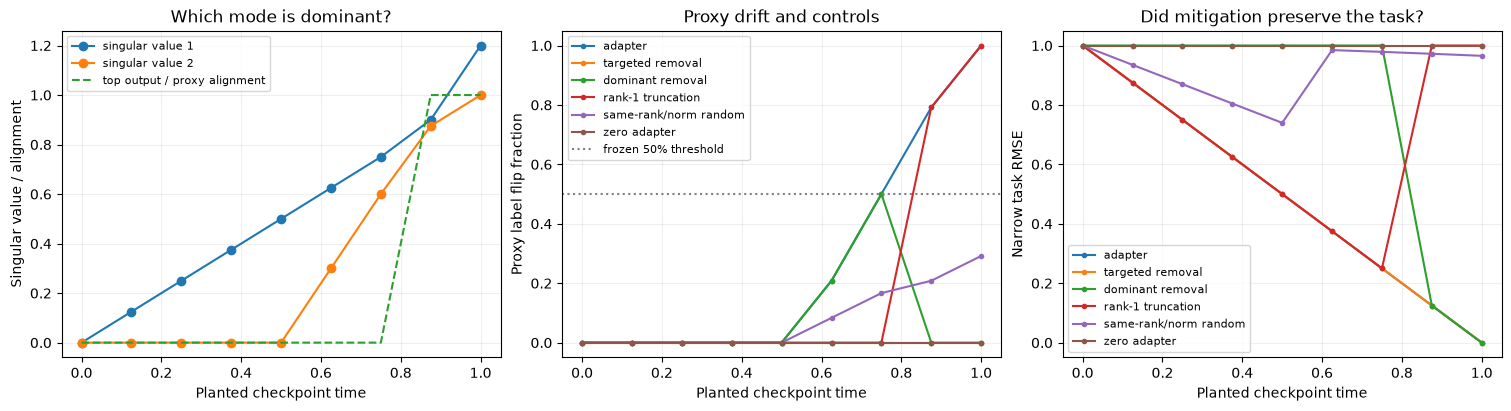

In [16]:
narrow_inputs = np.tile(np.eye(4)[0], (8, 1))
narrow_targets = np.ones(8)
narrow_direction = np.eye(4)[0]
conditions = {
    'adapter': list(updates),
    'targeted removal': [remove_output_direction(d, proxy_direction) for d in updates],
    'dominant removal': [remove_dominant_mode(d) for d in updates],
    'rank-1 truncation': [rank_projection(d, 1) for d in updates],
    'same-rank/norm random': [matched_random_update(d, int(np.linalg.matrix_rank(d)), 17) for d in updates],
    'zero adapter': [np.zeros_like(base) for _ in times],
}
curves = {name: np.array([flip_rate(base_margins, proxy_margins(proxy_inputs, base + d, proxy_direction, thresholds)) for d in ds]) for name, ds in conditions.items()}
errors = {name: np.array([task_rmse(narrow_inputs, base + d, narrow_direction, narrow_targets) for d in ds]) for name, ds in conditions.items()}
spectra = np.stack([np.linalg.svd(d, compute_uv=False) for d in updates])
alignments = np.array([top_output_alignment(d, proxy_direction) for d in updates])
print('50% proxy crossing:', first_crossing(times, curves['adapter'], .5))
print('Top-mode proxy alignment:', alignments)
for name in conditions:
    print(f'{name:25s} final flips={curves[name][-1]:.4f}; task RMSE={errors[name][-1]:.4f}')
utils.signature(times, spectra, curves, errors, alignments)
plt.show()

<details><summary>Expected output</summary>

The proxy crosses 50% at time 0.75. Top-mode alignment is zero through time 0.75 and equals 1 at times 0.875 and 1.0. At time 1, the adapter has proxy flips 1 and task RMSE 0; targeted removal and dominant removal both have proxy flips 0 and RMSE 0. The zero adapter has flips 0 and RMSE 1. The same-rank/norm random control has final proxy flips 0.2917 and task RMSE 0.9654. It is weaker on the proxy but does not fail completely: matching norm does not remove every relevant projection.

</details>

<details><summary>Help - how should I interpret this?</summary>

At time 0.75, the proxy coefficient is 0.6 while the task coefficient is 0.75. Removing the largest mode removes task improvement but leaves the proxy drift! At time 1, proxy coefficient 1.2 exceeds task coefficient 1.0, so the same spectral rule now repairs the proxy and preserves the task. Targeted removal uses the known causal proxy direction and works across the trajectory. Its unusually clean tradeoff follows from planted orthogonality.

The rank-1 truncation is a useful warning: reducing rank can discard the task mode while preserving the proxy mode at the last checkpoint. A rank-1 adapter is not inherently harmless, and rank alone says little about which inputs activate it.

</details>

## Summary of 3️⃣

An intervention needs a target and a cost measurement. Spectral prominence, behavioral relevance and narrow-task importance need not coincide. Comparing both readouts prevents a repaired proxy from hiding a destroyed task.

# 4️⃣ Prediction and scope

> ##### Learning Objectives
>
> - Explain a mismatch between spectral and behavioral onset.
> - State the additional model, data and behavioral evidence needed for an emergent-misalignment claim.

## Try it yourself

Change only `threshold_shift` below. First predict what happens to the first 50% crossing, and whether any singular value changes. Try `+0.3`: the behavior detector should move even though the adapter path is identical. This is a changed scientific condition (the readout's context offsets), rather than a fresh seed. You can also alter the detector threshold, but report it as a detector choice, not model behavior.

Then investigate an anomaly: why can the random control's task error get *worse* than the zero adapter's, despite identical update norm? Check its signed projection onto the task input/output pair; norm does not determine sign.

Changed 50% crossing: 0.875


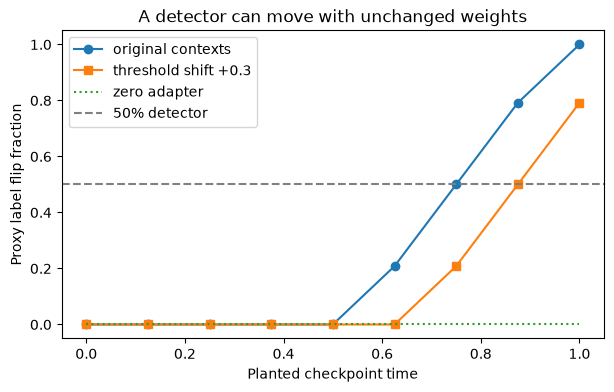

In [17]:
threshold_shift = 0.3  # editable context change; 0 recovers the worked example
changed_thresholds = thresholds + threshold_shift
changed_base = proxy_margins(proxy_inputs, base, proxy_direction, changed_thresholds)
changed_flips = np.array([flip_rate(changed_base, proxy_margins(proxy_inputs, base + d, proxy_direction, changed_thresholds)) for d in updates])
print('Changed 50% crossing:', first_crossing(times, changed_flips, .5))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(times, curves['adapter'], 'o-', label='original contexts')
ax.plot(times, changed_flips, 's-', label=f'threshold shift {threshold_shift:+.1f}')
ax.plot(times, curves['zero adapter'], ':', label='zero adapter')
ax.axhline(.5, color='grey', linestyle='--', label='50% detector')
ax.set(xlabel='Planted checkpoint time', ylabel='Proxy label flip fraction', title='A detector can move with unchanged weights')
ax.legend()
plt.show()

<details><summary>Expected output and interpretation</summary>

At threshold shift +0.3, the first sampled 50% crossing is 0.875 rather than 0.75. All adapter singular values are unchanged. This result was obtained by changing the behavioral measurement conditions, not by training a different adapter. If you already viewed it before forecasting, mark the outcome as exposed guided practice.

</details>

## Interpreting the result

The proxy's onset at 0.75 precedes the top-mode alignment switch at 0.875 on this coarse checkpoint grid. Neither is the planted coefficient's onset at 0.5. The apparent transition depends on the trajectory, threshold distribution, sample times and decision rule. To claim an empirically learned transition, you would need actual checkpointed training, a prespecified behavior metric, multiple relevant controls and measurements fine enough to distinguish a smooth curve from an abrupt change.

## Bridge to real LoRA and emergent misalignment

[Hu et al.](https://arxiv.org/abs/2106.09685) freeze pretrained weights and train low-rank factors; our factor shapes and dense-update convention implement that algebra, while our explicit matrix path substitutes for training. In a real module, collect $BA$ checkpoints without merging into the base, inspect both input and output singular vectors, and measure task and behavior on named datasets with recorded roles.

[Soligo et al.](https://arxiv.org/abs/2506.11618) study Qwen2.5-14B-Instruct with nine rank-1 adapters and use activation directions and adapter structure to investigate emergent misalignment. Their real model and behavioral evaluation are essential to their claim. One rank-1 *module* is not one scalar for the whole network; the collection spans layers, nonlinearities and contexts. Our example teaches the measurement and causal bookkeeping, not their empirical phenomenon.

[Betley et al.](https://arxiv.org/abs/2502.17424) report broad concerning behavior after narrow finetuning. No color-label statistic can stand in for that evaluation. A safe benign proxy is useful for validating code and practicing detector design; it cannot establish misalignment, safety or mitigation effectiveness in an LLM.

## Limitations

The path, output axes and orthogonality are planted; examples repeat two input vectors; there is no training, language generation or independent empirical evaluation. The random control matches rank and norm rather than the complete singular spectrum, and uses one visible seed. Singular-vector interpretation is unstable at degeneracy. We have not qualified a pretrained checkpoint, optimizer schedule, learned phase transition, activation-direction estimator or broad behavior judge. Native validation and all requirement-status promotion remain separate.

## Summary of 4️⃣

You can now implement a detector, predict how changing context thresholds moves it, and test a causal direction without mistaking a proxy for the target phenomenon. Record which parts of that reasoning survive when you remove the planted ground truth.

# ☆ Bonus

## Further research / anomaly hunting

1. Rotate input and output spaces by different orthogonal matrices. Rotate the readouts and inputs consistently. Does the proxy curve stay fixed while raw coordinate interpretations change?
2. Make the narrow-task readout overlap the proxy direction. Predict the unavoidable RMSE cost of projection before editing the fixture. Does the perfect tradeoff disappear?
3. Compare the original same-rank/norm control to one preserving every singular value while randomizing U and V. Which null hypothesis does each test?
4. Replace the hard label metric with mean margin and plot both. Which apparent discontinuities disappear? Does checkpoint spacing affect your confidence about onset?

### Further Reading

- [LoRA: Low-Rank Adaptation of Large Language Models](https://arxiv.org/abs/2106.09685): frozen weights and trainable low-rank factors.
- [Convergent Linear Representations of Emergent Misalignment](https://arxiv.org/abs/2506.11618): rank-1 adapter model organism, activation directions and adapter interpretation.
- [Emergent Misalignment: Narrow finetuning can produce broadly misaligned LLMs](https://arxiv.org/abs/2502.17424): the behavioral phenomenon that this benign proxy does not replicate.
- Return to 15.1 for factor/merge algebra and 15.2 for an actual adaptation comparison; retain their execution provenance and limitations.